# Customer Churn Prediction - Exploratory Data Analysis
Analyze customer churn datasets, feature distributions, and relationships.

In [20]:
from pathlib import Path
import pandas as pd
import numpy as np

DATASET_PATH = Path("../../datasets/customer_churn_dataset-training-master.csv")
df = pd.read_csv(DATASET_PATH)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (440833, 12)

First 5 Records:


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  str    
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  str    
 8   Contract Length    440832 non-null  str    
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), str(3)
memory usage: 40.4 MB

Missing Values:
CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Cal

In [23]:
import warnings
warnings.filterwarnings("ignore")

TARGET = "Churn"
print("Columns:", df.columns.tolist())
print("Rows with ALL values missing:", df.isnull().all(axis=1).sum())

# drop fully empty rows, then any row without a target
df = df.dropna(how="all").copy()
df = df.dropna(subset=[TARGET]).copy()
print("Rows with any remaining missing:", df.isnull().any(axis=1).sum())

# target -> 0/1 int (works if it's float 1.0/0.0 or Yes/No text)
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    df[TARGET] = (df[TARGET].astype(str).str.strip().str.lower()
                  .map({"yes": 1, "no": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0}))
assert df[TARGET].notna().all(), "Target has values I couldn't map"
df[TARGET] = df[TARGET].astype(int)

# drop ID columns (an ID has no predictive meaning)
id_cols = [c for c in df.columns
           if c.lower().replace("_", "").replace(" ", "") in ("customerid", "id")]
df = df.drop(columns=id_cols)
print("Dropped ID columns:", id_cols)

print("Duplicate rows:", df.duplicated().sum())
print("\nChurn rate:", round(df[TARGET].mean(), 4))
print(df[TARGET].value_counts())
print("Final shape:", df.shape)

Columns: ['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']
Rows with ALL values missing: 1
Rows with any remaining missing: 0
Dropped ID columns: ['CustomerID']
Duplicate rows: 0

Churn rate: 0.5671
Churn
1    249999
0    190833
Name: count, dtype: int64
Final shape: (440832, 11)


Gender
Female    0.667
Male      0.491 

Subscription Type
Basic       0.582
Premium     0.559
Standard    0.561 

Contract Length
Annual       0.461
Monthly      1.000
Quarterly    0.460 



Churn,0,1
Age,36.26,41.75
Tenure,32.28,30.47
Usage Frequency,16.26,15.46
Support Calls,1.59,5.14
Payment Delay,10.02,15.22
Total Spend,749.95,541.29
Last Interaction,13.01,15.60


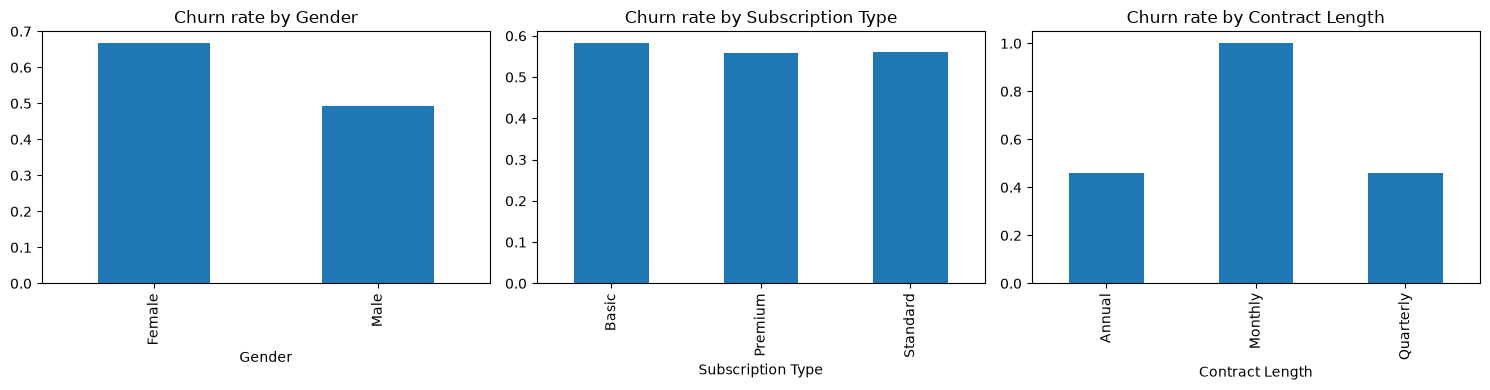

In [24]:
import matplotlib.pyplot as plt

cat_eda = df.select_dtypes(exclude="number").columns.tolist()
for c in cat_eda:
    print(df.groupby(c)[TARGET].mean().round(3).to_string(), "\n")

display(df.groupby(TARGET).mean(numeric_only=True).T.round(2))

if cat_eda:
    fig, axes = plt.subplots(1, len(cat_eda), figsize=(5 * len(cat_eda), 4))
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cat_eda):
        df.groupby(c)[TARGET].mean().plot(kind="bar", ax=ax, title=f"Churn rate by {c}")
    plt.tight_layout(); plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

# subsample of TRAIN only, used for fast CV and tuning
SAMPLE = min(60000, len(X_train))
X_s, _, y_s, _ = train_test_split(
    X_train, y_train, train_size=SAMPLE, stratify=y_train, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| CV subsample:", X_s.shape)

Numeric: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical: ['Gender', 'Subscription Type', 'Contract Length']
Train: (352665, 10) | Test: (88167, 10) | CV subsample: (60000, 10)


In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "dummy":  DummyClassifier(strategy="prior"),
    "logreg": LogisticRegression(max_iter=1000),
    "rf":     RandomForestClassifier(n_estimators=150, min_samples_leaf=3,
                                     random_state=42, n_jobs=-1),
    "xgb":    XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=5,
                            tree_method="hist", eval_metric="logloss",
                            random_state=42, n_jobs=-1),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scoring = ["accuracy", "average_precision", "roc_auc", "f1", "recall", "precision"]

rows = {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("clf", m)])
    res = cross_validate(pipe, X_s, y_s, cv=cv, scoring=scoring)
    rows[name] = {k.replace("test_", ""): v.mean()
                  for k, v in res.items() if k.startswith("test_")}
    print("done:", name)

results = pd.DataFrame(rows).T.round(4)
display(results)

done: dummy
done: logreg
done: rf
done: xgb


,accuracy,average_precision,roc_auc,f1,recall,precision
dummy,0.5671,0.5671,0.5000,0.7238,1.0000,0.5671
logreg,0.8969,0.9749,0.9606,0.9072,0.8885,0.9267
rf,0.9937,0.9999,0.9999,0.9944,0.9894,0.9994
xgb,0.9998,1.0000,1.0000,0.9999,0.9998,1.0000


In [27]:
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid

best_name = results.drop(index="dummy")["average_precision"].idxmax()
print("Best by PR-AUC:", best_name)

grids = {
    "logreg": {"clf__C": [0.01, 0.1, 1, 10]},
    "rf":  {"clf__n_estimators": [100, 200], "clf__max_depth": [None, 10, 20],
            "clf__min_samples_leaf": [1, 3, 5]},
    "xgb": {"clf__max_depth": [3, 4, 5, 6], "clf__learning_rate": [0.05, 0.1, 0.2],
            "clf__n_estimators": [200, 300, 400], "clf__subsample": [0.8, 1.0]},
}
grid = grids[best_name]
n_iter = min(8, len(list(ParameterGrid(grid))))

base = Pipeline([("pre", pre), ("clf", clone(models[best_name]))])
search = RandomizedSearchCV(base, grid, n_iter=n_iter, scoring="average_precision",
                            cv=3, random_state=42, n_jobs=1)
search.fit(X_s, y_s)
print("Best params:", search.best_params_)
print("Best CV PR-AUC:", round(search.best_score_, 4))

Best by PR-AUC: xgb
Best params: {'clf__subsample': 0.8, 'clf__n_estimators': 300, 'clf__max_depth': 3, 'clf__learning_rate': 0.2}
Best CV PR-AUC: 1.0


In [28]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof = cross_val_predict(search.best_estimator_, X_s, y_s, cv=cv,
                        method="predict_proba")[:, 1]
p, r, t = precision_recall_curve(y_s, oof)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
i = int(np.argmax(f1s))
thr = float(t[i])
print(f"Chosen threshold: {thr:.3f} -> precision {p[i]:.3f}, recall {r[i]:.3f}, F1 {f1s[i]:.3f}")

Chosen threshold: 0.736 -> precision 1.000, recall 1.000, F1 1.000


In [29]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, roc_auc_score)

final = clone(search.best_estimator_).fit(X_train, y_train)   # full train data
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= thr).astype(int)

print(classification_report(y_test, pred, digits=4))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
print("PR-AUC :", round(average_precision_score(y_test, proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("Majority-class accuracy:", round(max(y_test.mean(), 1 - y_test.mean()), 4))

              precision    recall  f1-score   support

           0     0.9998    1.0000    0.9999     38167
           1     1.0000    0.9999    0.9999     50000

    accuracy                         0.9999     88167
   macro avg     0.9999    0.9999    0.9999     88167
weighted avg     0.9999    0.9999    0.9999     88167

Confusion matrix:
 [[38167     0]
 [    7 49993]]
PR-AUC : 1.0
ROC-AUC: 1.0
Majority-class accuracy: 0.5671


Support Calls        0.1686
Total Spend          0.0293
Age                  0.0270
Contract Length      0.0173
Payment Delay        0.0162
Gender               0.0046
Last Interaction     0.0043
Tenure               0.0010
Usage Frequency      0.0006
Subscription Type    0.0001
dtype: float64

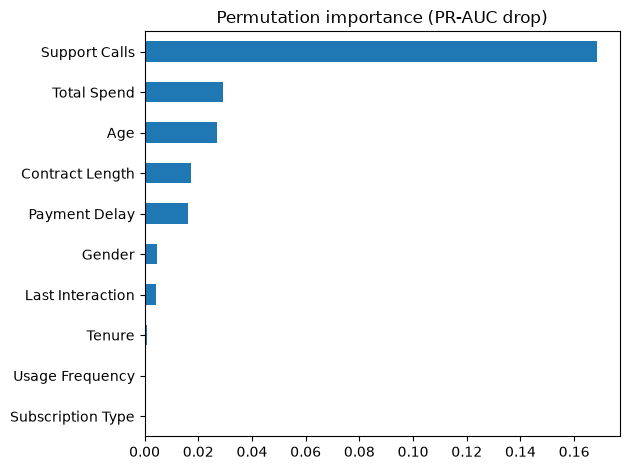

In [30]:
from sklearn.inspection import permutation_importance

n = min(5000, len(X_test))
Xs = X_test.sample(n, random_state=42)
ys = y_test.loc[Xs.index]
pi = permutation_importance(final, Xs, ys, scoring="average_precision",
                            n_repeats=3, random_state=42, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=Xs.columns).sort_values(ascending=False)
display(imp.round(4))
imp.plot(kind="barh", title="Permutation importance (PR-AUC drop)").invert_yaxis()
plt.tight_layout(); plt.show()

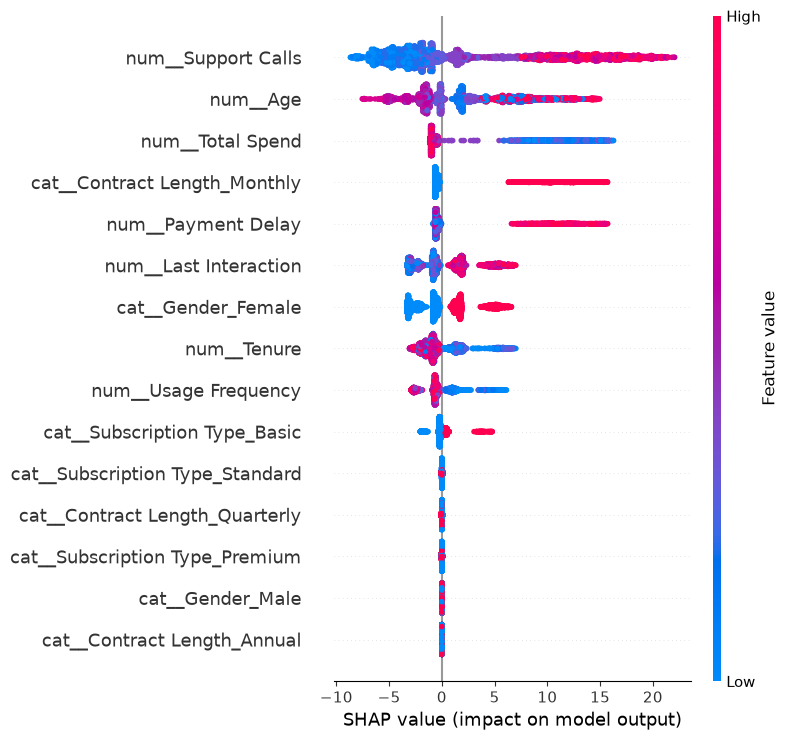

In [31]:
import shap
if best_name == "xgb":
    Xt = final.named_steps["pre"].transform(Xs)
    names = final.named_steps["pre"].get_feature_names_out()
    sv = shap.TreeExplainer(final.named_steps["clf"]).shap_values(Xt)
    shap.summary_plot(sv, Xt, feature_names=names)
else:
    print("Skipping SHAP: best model is", best_name, "- permutation importance is enough")

In [32]:
import joblib
Path("../models").mkdir(exist_ok=True)
joblib.dump({"model": final, "threshold": thr}, "../models/churn_model.joblib")
print("saved")

saved
